# XSTAR run output viewer

A simple, path-driven notebook for exploring **the raw outputs of one XSTAR run**.

1. Set `path_to_xstar` in Section 1.
2. Run the notebook from top to bottom.
3. Use the tables, plots, and FITS browser to inspect the outputs that exist in that run directory.

The notebook discovers the standard XSTAR products automatically, checks every FITS extension, and also exposes additional FITS/log files so that version-specific outputs are not silently ignored. It requires `numpy`, `pandas`, `matplotlib`, `astropy`, and `ipywidgets` in the active Jupyter environment.

### Outputs covered

| Output | What you can inspect |
|---|---|
| `xout_spect1.fits` | Incident, transmitted, inward-emitted, and outward-emitted spectrum (with lines binned into the continuum) |
| `xout_cont1.fits` | The corresponding continuum-only spectrum |
| `xout_lines1.fits` | Strong emission-line list, wavelengths, luminosities, and optical depths |
| `xout_rrc1.fits` | Radiative recombination continua (RRCs) |
| `xout_abund1.fits` | Zone-by-zone ion fractions, ionic columns, heating, and cooling |
| `xout_step.log` | Run parameters, radial/thermal diagnostics, strongest lines/RRCs, and energy budget |
| `xoNN_detail*.fits` / `xoNN_detal*.fits` | Optional detailed level-population, line, RRC, and continuum information by spatial zone (`lwrite=1`) |

The detailed `xoNN_...fits` products can be large. They are inventoried automatically but are read only when selected in the interactive FITS browser.

**Documentation:** [XSTAR Manual, Release 2.5x (PDF)](https://heasarc.gsfc.nasa.gov/docs/software/xstar/docs/xstarmanual.pdf)


## 1. Imports and run configuration

In [3]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
import astropy.units as u
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": False, "grid.alpha": 0.25, "font.size": 10})

In [4]:
# Edit this path to the directory containing the raw products of ONE XSTAR run
path_to_xstar = Path("/data-fast/dragon/vicente/iongrid/runs/run_20261029_htc_lhs/points/lhs00001").expanduser()

# Usually all files are directly inside path_to_xstar. Set True only if your run wrapper places outputs in nested subdirectories:
SEARCH_SUBDIRECTORIES = False

# Display choices (these affect presentation only; the FITS data are unchanged):
PLOT_ENERGY_UNIT = "keV"       
TABLE_PREVIEW_ROWS = 20
LOG_PREVIEW_CHARS = None       # None = display complete log files

## 2. Discover the files produced by this run

The standard files are expected in the run directory. The notebook also detects any other FITS and log files and keeps them available in the general inspector.

In [5]:
if not path_to_xstar.is_dir():
    raise FileNotFoundError(
        f"XSTAR run directory does not exist: {path_to_xstar}. Edit path_to_xstar in Section 1 and run the notebook again.")

EXPECTED_PRODUCTS = {
    "xout_spect1.fits": "Spectrum including line emission binned into the continuum",
    "xout_cont1.fits": "Continuum-only spectrum (without lines binned into it)",
    "xout_lines1.fits": "Strong emission-line list",
    "xout_abund1.fits": "Zone-by-zone ion fractions, ionic columns, heating, and cooling",
    "xout_rrc1.fits": "Radiative recombination continuum (RRC) list",
    "xout_step.log": "XSTAR run log and diagnostics",
}

def _product_description(filename):
    name = filename.lower()
    if name in EXPECTED_PRODUCTS:
        return EXPECTED_PRODUCTS[name]
    if re.match(r"^xo\d{2}_(?:detail|detal)\d*\.fits$", name):
        if "detail2" in name or "detal2" in name:
            return "Optional detailed line emissivities/opacity by zone (lwrite=1)"
        if "detail3" in name or "detal3" in name:
            return "Optional detailed RRC emissivities/opacity by zone (lwrite=1)"
        if "detail4" in name or "detal4" in name:
            return "Optional detailed continuum spectra/emissivities by zone (lwrite=1)"
        return "Optional detailed ionic level populations by zone (lwrite=1)"
    if name.endswith((".fits", ".fit", ".fts")):
        return "Additional FITS product (available in the general FITS browser)"
    if name.endswith((".log", ".out")):
        return "Additional text/log output"
    return "Other file in the run directory"

all_paths = sorted((p for p in (path_to_xstar.rglob("*") if SEARCH_SUBDIRECTORIES else path_to_xstar.iterdir()) if p.is_file()), key=lambda p: str(p).lower())
fits_paths = [p for p in all_paths if p.suffix.lower() in {".fits", ".fit", ".fts"}]
log_paths = [p for p in all_paths if p.suffix.lower() in {".log", ".out"}]

file_inventory = pd.DataFrame([
    {
        "file": str(p.relative_to(path_to_xstar)),
        "type": p.suffix.lower() or "(no extension)",
        "size [MiB]": round(p.stat().st_size / 1024**2, 3),
        "description": _product_description(p.name),
    }
    for p in all_paths
])

print(f"Run directory: {path_to_xstar.resolve()}")
print(f"Files found: {len(all_paths)} | FITS files: {len(fits_paths)} | log/output files: {len(log_paths)}")
display(file_inventory if not file_inventory.empty else pd.DataFrame({"message": ["No files found in this directory."]}))

# Map standard products to their discovered paths (also works when SEARCH_SUBDIRECTORIES=True):
standard_paths = {
    name: next((p for p in all_paths if p.name.lower() == name.lower()), path_to_xstar / name)
    for name in EXPECTED_PRODUCTS
}
found_basenames = {p.name.lower() for p in all_paths}
missing_standard = [name for name in EXPECTED_PRODUCTS if name.lower() not in found_basenames]
if missing_standard:
    print("\nStandard products not found (this is not necessarily an error):")
    for name in missing_standard:
        print(f"  - {name}")

if not fits_paths:
    print("\nNo FITS files were found. Check the run directory or SEARCH_SUBDIRECTORIES setting.")


Run directory: /data-fast/dragon/vicente/iongrid/runs/run_20261029_htc_lhs/points/lhs00001
Files found: 11 | FITS files: 5 | log/output files: 1


,file,type,size [MiB],description
0,lhs00001.npz,.npz,0.223,Other file in the run directory
1,xout_abund1.fits,.fits,0.401,"Zone-by-zone ion fractions, ionic columns, heating, and cooling"
2,xout_cont1.fits,.fits,0.673,Continuum-only spectrum (without lines binned into it)
3,xout_lines1.fits,.fits,0.091,Strong emission-line list
4,xout_rrc1.fits,.fits,1.296,Radiative recombination continuum (RRC) list
5,xout_spect1.fits,.fits,0.673,Spectrum including line emission binned into the continuum
6,xout_step.log,.log,0.005,XSTAR run log and diagnostics
7,xstar-params.json,.json,0.000,Other file in the run directory
8,xstar.exitcode,.exitcode,0.000,Other file in the run directory
9,xstar.stderr,.stderr,0.000,Other file in the run directory


## 3. Inspect all FITS extensions (HDUs)

This inventory reads the FITS structure and column definitions without copying every table into memory. It is especially useful for the optional per-zone files, which can be large.

In [6]:
def inventory_fits_file(filepath):
    rows = []
    with fits.open(filepath, memmap=False, lazy_load_hdus=True) as hdul:
        for hdu_index, hdu in enumerate(hdul):
            is_table = isinstance(hdu, (fits.BinTableHDU, fits.TableHDU))
            columns = list(hdu.columns.names or []) if is_table else []
            rows.append({
                "file": str(filepath.relative_to(path_to_xstar)),
                "HDU": hdu_index,
                "class": type(hdu).__name__,
                "EXTNAME": hdu.header.get("EXTNAME", "(primary / unnamed)"),
                "rows": hdu.header.get("NAXIS2") if is_table else None,
                "columns": ", ".join(columns),
            })
    return rows

inventory_rows = []
for filepath in fits_paths:
    try:
        inventory_rows.extend(inventory_fits_file(filepath))
    except Exception as exc:
        inventory_rows.append({
            "file": str(filepath.relative_to(path_to_xstar)),
            "HDU": None,
            "class": "READ ERROR",
            "EXTNAME": "",
            "rows": None,
            "columns": str(exc),
        })

hdu_inventory = pd.DataFrame(inventory_rows)
display(hdu_inventory if not hdu_inventory.empty else pd.DataFrame({"message": ["No FITS HDUs to inspect."]}))


,file,HDU,class,EXTNAME,rows,columns
0,xout_abund1.fits,0,PrimaryHDU,(primary / unnamed),NaN,
1,xout_abund1.fits,1,TableHDU,ABUNDANCES,20.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, h_i, he_i, he_..."
2,xout_abund1.fits,2,TableHDU,COLUMNS,1.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, h_i, he_i, he_..."
3,xout_abund1.fits,3,TableHDU,HEATING,20.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, hydrogen, heli..."
4,xout_abund1.fits,4,TableHDU,COOLING,20.0,"radius, delta_r, ion_parameter, x_e, n_p, pressure, temperature, frac_heat_error, hydrogen, heli..."
5,xout_cont1.fits,0,PrimaryHDU,(primary / unnamed),NaN,
6,xout_cont1.fits,1,BinTableHDU,PARAMETERS,56.0,"index, parameter, value, type, comment"
7,xout_cont1.fits,2,TableHDU,XSTAR_SPECTRA,9999.0,"energy, incident, transmitted, emit_inward, emit_outward"
8,xout_lines1.fits,0,PrimaryHDU,(primary / unnamed),NaN,
9,xout_lines1.fits,1,BinTableHDU,PARAMETERS,56.0,"index, parameter, value, type, comment"


## 4. Read the run parameters

The standard XSTAR FITS products usually contain a `PARAMETERS` extension listing the input parameters. This cell uses the first such extension it finds.

In [7]:
def _read_table(filepath, hdu_index):
    """Read one FITS table HDU into a DataFrame; vector columns remain as array-valued cells."""
    with fits.open(filepath, memmap=False) as hdul:
        hdu = hdul[hdu_index]
        if not isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)) or hdu.data is None:
            raise TypeError(f"HDU {hdu_index} in {filepath.name} is not a populated table.")
        names = list(hdu.columns.names or [])
        data = {}
        for name in names:
            arr = np.asarray(hdu.data[name])
            data[name] = arr if arr.ndim <= 1 else list(arr)
        frame = pd.DataFrame(data)
        units = {col.name: col.unit for col in hdu.columns}
        header = hdu.header.copy()
    return frame, units, header


def _find_hdu_index(filepath, extname=None, required_columns=None):
    required_columns = [str(x).lower() for x in (required_columns or [])]
    with fits.open(filepath, memmap=False, lazy_load_hdus=True) as hdul:
        for i, hdu in enumerate(hdul):
            if not isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)):
                continue
            name = str(hdu.header.get("EXTNAME", "")).strip().lower()
            if extname is not None and name != extname.lower():
                continue
            names = [str(x).lower() for x in (hdu.columns.names or [])]
            if all(col in names for col in required_columns):
                return i
    return None


parameter_result = None
for filepath in fits_paths:
    idx = _find_hdu_index(filepath, extname="PARAMETERS")
    if idx is not None:
        parameter_result = (filepath, idx)
        break

if parameter_result is None:
    print("No PARAMETERS extension was found in the discovered FITS files.")
else:
    parameter_file, parameter_hdu = parameter_result
    parameter_table, parameter_units, _ = _read_table(parameter_file, parameter_hdu)
    print(f"Parameters read from: {parameter_file.name} (HDU {parameter_hdu})")
    display(parameter_table)


Parameters read from: xout_cont1.fits (HDU 1)


,index,parameter,value,type,comment
0,1,cfrac,1.000000e+00,real,
1,2,temperature,4.000000e+02,real,Units of 10**4 K
2,3,lcpres,0.000000e+00,integer,"1=yes, 0=no"
3,4,pressure,3.000000e-02,real,dynes/cm**2
4,5,density,1.000000e+12,real,cm**(-3)
5,6,spectrum,0.000000e+00,string,pow
6,7,spectrum_file,0.000000e+00,string,
7,8,spectun,0.000000e+00,integer,"0=energy, 1=photons"
8,9,trad,-6.892097e-01,real,or alpha
9,10,rlrad38,1.000000e+09,real,/10**38 erg/sec


## 5. Plot the spectral outputs

`xout_spect1.fits` contains the spectrum with lines binned into the continuum; `xout_cont1.fits` contains the continuum without those line contributions. The XSTAR documentation gives the energy column in **eV** and the specific-luminosity columns in units of `10^38 erg s^-1 erg^-1`.

The plot below converts the horizontal axis to `PLOT_ENERGY_UNIT` for display only. FITS values are not modified. It plots whichever of `incident`, `transmitted`, `emit_inward`, and `emit_outward` are present.

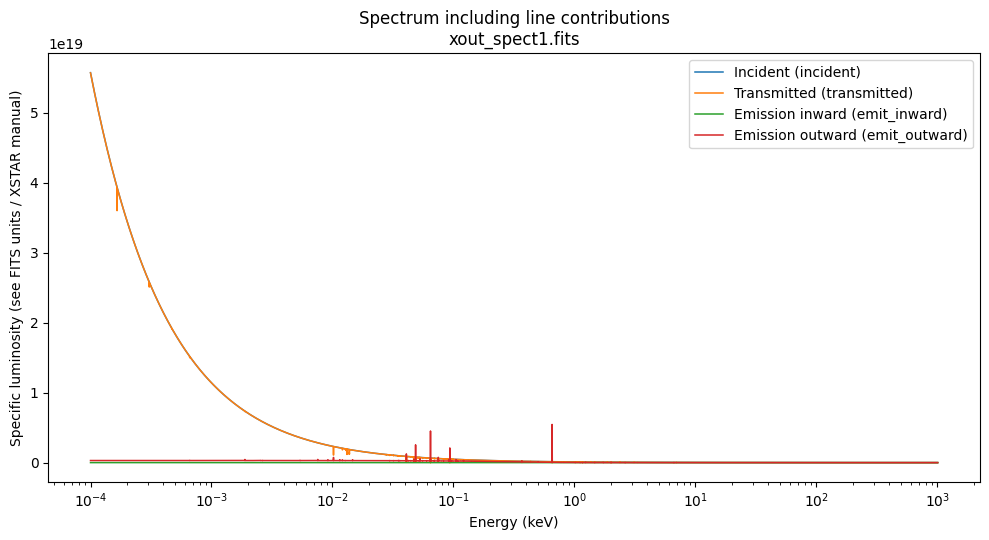

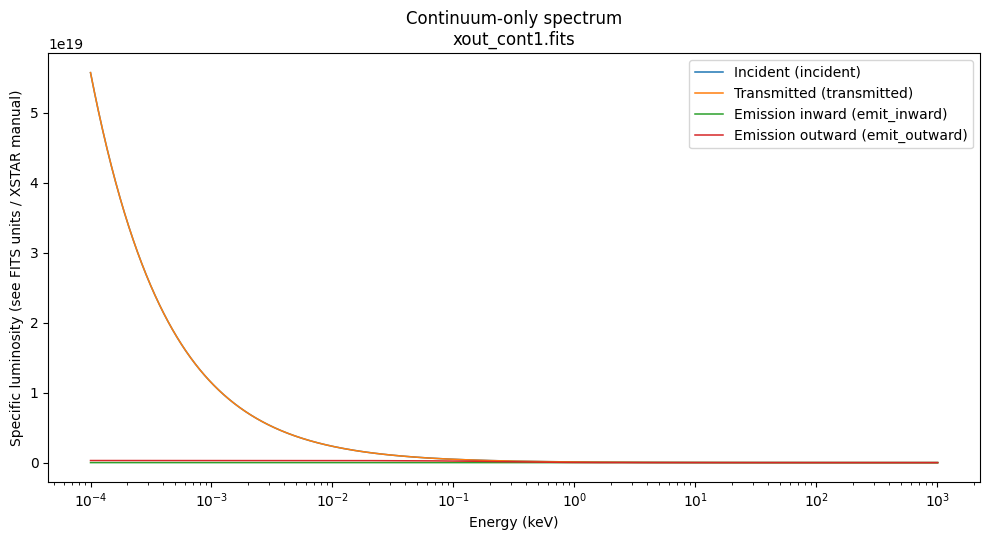

In [8]:
def _normalise_name(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).strip().lower())


def _matching_column(columns, candidates):
    normalised = {_normalise_name(c): c for c in columns}
    for candidate in candidates:
        key = _normalise_name(candidate)
        if key in normalised:
            return normalised[key]
    return None


def _scalar_numeric_columns(frame):
    result = []
    for col in frame.columns:
        arr = np.asarray(frame[col])
        if arr.ndim == 1 and arr.dtype.kind in "biufc":
            result.append(col)
    return result


def _energy_axis_values(values, unit, filepath):
    """Convert energy to PLOT_ENERGY_UNIT; standard xout spectra use eV per the manual."""
    values = np.asarray(values, dtype=float)
    source_unit = unit
    if source_unit in (None, ""):
        # The manual specifies eV for xout_spect1.fits and xout_cont1.fits.
        source_unit = "eV" if filepath.name.lower() in {"xout_spect1.fits", "xout_cont1.fits"} else None
    if source_unit is None:
        return values, "energy (FITS unit not specified; values unconverted)"
    try:
        converted = (values * u.Unit(source_unit)).to_value(u.Unit(PLOT_ENERGY_UNIT))
        return converted, f"Energy ({PLOT_ENERGY_UNIT})"
    except Exception:
        warnings.warn(f"Could not convert energy unit {source_unit!r}; plotting raw values.")
        return values, f"Energy ({source_unit}; unconverted)"


SPECTRAL_COLUMNS = [
    ("Incident", ["incident"]),
    ("Transmitted", ["transmitted"]),
    ("Emission inward", ["emit_inward", "emitinward"]),
    ("Emission outward", ["emit_outward", "emitoutward"]),
]


def plot_spectral_file(filepath):
    hdu_index = _find_hdu_index(filepath, extname="XSTAR_SPECTRA", required_columns=["energy"])
    if hdu_index is None:
        hdu_index = _find_hdu_index(filepath, required_columns=["energy"])
    if hdu_index is None:
        print(f"No table with an energy column was found in {filepath.name}.")
        return

    frame, units, _ = _read_table(filepath, hdu_index)
    energy_col = _matching_column(frame.columns, ["energy"])
    if energy_col is None:
        print(f"No energy column found in {filepath.name}.")
        return
    energy = np.asarray(frame[energy_col], dtype=float).squeeze()
    if energy.ndim != 1:
        print(f"Energy column in {filepath.name} is not one-dimensional; inspect it in Section 9.")
        return
    energy_plot, energy_label = _energy_axis_values(energy, units.get(energy_col), filepath)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    plotted = 0
    all_plotted_values_positive = True
    for label, candidates in SPECTRAL_COLUMNS:
        col = _matching_column(frame.columns, candidates)
        if col is None:
            continue
        values = np.asarray(frame[col], dtype=float).squeeze()
        if values.ndim != 1 or values.size != energy_plot.size:
            print(f"Skipping {col}: it is not a scalar value per energy bin.")
            continue
        mask = np.isfinite(energy_plot) & np.isfinite(values) & (energy_plot > 0)
        if np.any(values[mask] <= 0):
            all_plotted_values_positive = False
        if mask.sum() == 0:
            continue
        ax.plot(energy_plot[mask], values[mask], lw=1.1, label=f"{label} ({col})")
        plotted += 1

    if plotted == 0:
        plt.close(fig)
        print(f"No compatible spectral columns were found in {filepath.name}; use Section 9 to inspect it.")
        return
    ax.set_xscale("log")
    if all_plotted_values_positive:
        ax.set_yscale("log")
    ax.set_xlabel(energy_label)
    ax.set_ylabel("Specific luminosity (see FITS units / XSTAR manual)")
    title = "Spectrum including line contributions" if filepath.name.lower() == "xout_spect1.fits" else "Continuum-only spectrum"
    ax.set_title(f"{title}\n{filepath.name}")
    ax.legend()
    fig.tight_layout()
    plt.show()


spectral_files = [standard_paths[name] for name in ("xout_spect1.fits", "xout_cont1.fits") if standard_paths[name].is_file()]
if spectral_files:
    for spectral_file in spectral_files:
        plot_spectral_file(spectral_file)
else:
    print("Neither xout_spect1.fits nor xout_cont1.fits was found.")


## 6. Inspect and plot the line and RRC lists

The line and RRC files are **transition lists**, not spectra sampled on the continuum energy grid. Their x-axes therefore use wavelength (line list) or transition energy (RRC list). Use the dropdown to choose which numeric quantity to plot.

In [9]:
def show_transition_output(filename, extname, x_candidates, title, x_label, preferred_y_candidates):
    filepath = standard_paths.get(filename, path_to_xstar / filename)
    if not filepath.is_file():
        print(f"{filename} not found; skipping this section.")
        return

    idx = _find_hdu_index(filepath, extname=extname)
    if idx is None:
        idx = _find_hdu_index(filepath)
    if idx is None:
        print(f"No table HDU found in {filename}.")
        return

    frame, units, _ = _read_table(filepath, idx)
    x_col = _matching_column(frame.columns, x_candidates)
    if x_col is None:
        print(f"Could not identify the x-axis column in {filename}. Available columns: {list(frame.columns)}")
        display(frame.head(TABLE_PREVIEW_ROWS))
        return

    print(f"{filename}: {len(frame):,} row(s); preview:")
    display(frame.head(TABLE_PREVIEW_ROWS))

    numeric = _scalar_numeric_columns(frame)
    y_options = [col for col in numeric if col != x_col]
    if not y_options:
        print("No scalar numeric columns are available for plotting.")
        return
    default_y = _matching_column(y_options, preferred_y_candidates) or y_options[0]
    max_n = max(1, len(frame))

    def _plot(y_column=default_y, number_to_plot=max_n):
        x = np.asarray(frame[x_col], dtype=float)
        y = np.asarray(frame[y_column], dtype=float)
        mask = np.isfinite(x) & np.isfinite(y)
        if mask.sum() == 0:
            print("No finite values to plot.")
            return
        x, y = x[mask], y[mask]
        if number_to_plot < x.size:
            keep = np.argsort(np.abs(y))[-number_to_plot:]
            x, y = x[keep], y[keep]
        order = np.argsort(x)
        x, y = x[order], y[order]

        fig, ax = plt.subplots(figsize=(10, 4.8))
        ax.scatter(x, y, s=16, alpha=0.8)
        if np.all(x > 0):
            ax.set_xscale("log")
        if np.all(y > 0):
            ax.set_yscale("log")
        x_unit = units.get(x_col)
        y_unit = units.get(y_column)
        ax.set_xlabel(f"{x_label} [{x_unit}]" if x_unit else x_label)
        ax.set_ylabel(f"{y_column} [{y_unit}]" if y_unit else y_column)
        ax.set_title(f"{title}: {y_column}")
        fig.tight_layout()
        plt.show()

    controls = widgets.interactive(
        _plot,
        y_column=widgets.Dropdown(options=y_options, value=default_y, description="Y column:"),
        number_to_plot=widgets.IntSlider(
            value=max_n, min=1, max=max_n, step=max(1, max_n // 100),
            description="Points:", continuous_update=False,
            style={"description_width": "initial"},
        ),
    )
    display(controls)


show_transition_output(
    "xout_lines1.fits", "XSTAR_LINES", ["wavelength"],
    "XSTAR emission-line list", "Wavelength", ["emit_outward", "emit_inward"],
)

show_transition_output(
    "xout_rrc1.fits", "XSTAR_SPECTRA", ["energy"],
    "XSTAR radiative recombination continua", "Transition energy", ["emit_outward", "emit_inward"],
)


xout_lines1.fits: 600 row(s); preview:


,index,ion,lower_level,upper_level,wavelength,emit_inward,emit_outward,depth_inward,depth_outward
0,7765,o_viii,1s1.2S_1/2,1s0.2p1.2P_3/2,18.96710,0.0,6012520.0,63.248100,0.0
1,7764,o_viii,1s1.2S_1/2,1s0.2p1.2P_1/2,18.97250,0.0,3085370.0,31.651100,0.0
2,397206,fe_xxiv,2s1.2S_1/2,2s0.2p1.2P_3/2,192.01700,0.0,690498.0,47.631000,0.0
3,397883,fe_xxv,1s2.1S_0,1s1.2s1.3S_1,1.86819,0.0,493543.0,0.000011,0.0
4,395088,fe_xxiii,2s2.1S_0,2s1.2p1.1P_1,132.90600,0.0,449429.0,53.140100,0.0
5,397205,fe_xxiv,2s1.2S_1/2,2s0.2p1.2P_1/2,255.09000,0.0,280573.0,23.874200,0.0
6,27764,si_xiv,1s1.2S_1/2,1s0.2p1.2P_3/2,6.18042,0.0,249841.0,28.470100,0.0
7,397887,fe_xxv,1s2.1S_0,1s1.2p1.3P_1,1.85952,0.0,209627.0,2.071600,0.0
8,27763,si_xiv,1s1.2S_1/2,1s0.2p1.2P_1/2,6.18583,0.0,185136.0,14.272500,0.0
9,36699,s_xvi,1s1.2S_1/2,1s0.2p1.2P_3/2,4.72735,0.0,165825.0,18.287000,0.0


interactive(children=(Dropdown(description='Y column:', index=2, options=('index', 'emit_inward', 'emit_outwar…

xout_rrc1.fits: 12,526 row(s); preview:


,index,ion,level,energy,emit_outward,emit_inward,depth_outward,depth_inward
0,1,h_i,1s0.6f1.2F,0.377700,3.888300,3.888300,0.000000e+00,0.0
1,2,h_i,1s0.5f1.2F_7/2,0.545493,3.366500,3.366500,1.183630e-06,0.0
2,3,h_i,1s0.5f1.2F_5/2,0.545494,2.524880,2.524880,8.866030e-07,0.0
3,4,h_i,1s0.6h1.2H,0.377700,0.171880,0.171880,0.000000e+00,0.0
4,5,h_i,1s0.6g1.2G,0.377700,0.960811,0.960811,0.000000e+00,0.0
5,6,h_i,1s0.5s1.2S_1/2,0.545497,1904.500000,1904.500000,3.193460e-07,0.0
6,7,h_i,1s0.2p1.2P_1/2,3.401190,1208.080000,1208.080000,1.518280e-06,0.0
7,8,h_i,1s0.2p1.2P_3/2,3.401270,2416.190000,2416.190000,2.239370e-06,0.0
8,9,h_i,1s0.6p1.2P,0.377700,125.618000,125.618000,0.000000e+00,0.0
9,10,h_i,1s0.6s1.2S,0.377700,990.316000,990.316000,1.384110e-06,0.0


interactive(children=(Dropdown(description='Y column:', index=1, options=('index', 'emit_outward', 'emit_inwar…

## 7. Explore the ion fractions, ionic columns, heating, and cooling

`xout_abund1.fits` normally contains the extensions `ABUNDANCES`, `COLUMNS`, `HEATING`, and `COOLING`.

- `ABUNDANCES`: ion fractions and local physical conditions as a function of depth/zone.
- `COLUMNS`: ionic column densities.
- `HEATING` and `COOLING`: heating/cooling-rate information.

For the first two tables, select any numeric column to plot against radius (or another numeric x-axis). This also lets you select individual ion columns, whose names depend on the elements/ions present in the calculation.

In [10]:
def show_abundance_extension(extname, default_y_candidates=()):
    filepath = standard_paths["xout_abund1.fits"]
    if not filepath.is_file():
        return
    idx = _find_hdu_index(filepath, extname=extname)
    if idx is None:
        print(f"Extension {extname!r} not found in xout_abund1.fits.")
        return

    frame, units, _ = _read_table(filepath, idx)
    print(f"{extname}: {len(frame):,} row(s), {len(frame.columns)} column(s); preview:")
    display(frame.head(TABLE_PREVIEW_ROWS))

    numeric = _scalar_numeric_columns(frame)
    if not numeric:
        print("No scalar numeric columns found in this extension.")
        return

    x_default = _matching_column(numeric, ["radius"]) or numeric[0]
    y_options = [col for col in numeric if col != x_default]
    if not y_options:
        return
    y_default = _matching_column(y_options, list(default_y_candidates)) or y_options[0]

    def _plot(x_column=x_default, y_column=y_default, x_scale="log", y_scale="log"):
        x = np.asarray(frame[x_column], dtype=float)
        y = np.asarray(frame[y_column], dtype=float)
        mask = np.isfinite(x) & np.isfinite(y)
        if x_scale == "log":
            mask &= x > 0
        if y_scale == "log":
            mask &= y > 0
        if mask.sum() == 0:
            print("No finite points satisfy the selected axis scales.")
            return
        order = np.argsort(x[mask])
        x_plot = x[mask][order]
        y_plot = y[mask][order]
        fig, ax = plt.subplots(figsize=(10, 4.8))
        ax.plot(x_plot, y_plot, marker=".", ms=4, lw=1)
        ax.set_xscale(x_scale)
        ax.set_yscale(y_scale)
        x_unit = units.get(x_column)
        y_unit = units.get(y_column)
        ax.set_xlabel(f"{x_column} [{x_unit}]" if x_unit else x_column)
        ax.set_ylabel(f"{y_column} [{y_unit}]" if y_unit else y_column)
        ax.set_title(f"xout_abund1.fits — {extname}")
        fig.tight_layout()
        plt.show()

    controls = widgets.interactive(
        _plot,
        x_column=widgets.Dropdown(options=numeric, value=x_default, description="X column:"),
        y_column=widgets.Dropdown(options=y_options, value=y_default, description="Y column:"),
        x_scale=widgets.ToggleButtons(options=["linear", "log"], value="log", description="X scale:"),
        y_scale=widgets.ToggleButtons(options=["linear", "log"], value="log", description="Y scale:"),
    )
    display(controls)


if (path_to_xstar / "xout_abund1.fits").is_file():
    show_abundance_extension("ABUNDANCES", ["temperature", "ion_parameter", "x_e", "n_p"])
    show_abundance_extension("COLUMNS")
    show_abundance_extension("HEATING")
    show_abundance_extension("COOLING")
else:
    print("xout_abund1.fits not found.")


ABUNDANCES: 20 row(s), 473 column(s); preview:


,radius,delta_r,ion_parameter,x_e,n_p,pressure,temperature,frac_heat_error,h_i,he_i,he_ii,li_i,li_ii,li_iii,be_i,be_ii,be_iii,be_iv,b_i,b_ii,b_iii,b_iv,b_v,c_i,c_ii,c_iii,c_iv,c_v,c_vi,n_i,...,zn_i,zn_ii,zn_iii,zn_iv,zn_v,zn_vi,zn_vii,zn_viii,zn_ix,zn_x,zn_xi,zn_xii,zn_xiii,zn_xiv,zn_xv,zn_xvi,zn_xvii,zn_xviii,zn_xix,zn_xx,zn_xxi,zn_xxii,zn_xxiii,zn_xxiv,zn_xxv,zn_xxvi,zn_xxvii,zn_xxviii,zn_xxix,zn_xxx
0,1.376190e+16,0.000000e+00,2.72264,1.0,1.000000e+12,0.03,400.0,0.063709,7.567180e-09,0.0,7.819200e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.377470e-07,0.001010,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.869050e-08,0.000004,0.000193,0.001586,0.008464,0.026527,0.063469,0.093712,0.129636,0.141806,0.378371,0.135593
1,1.376190e+16,0.000000e+00,2.72264,1.0,1.000000e+12,0.03,400.0,0.066380,7.730490e-09,0.0,7.846670e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.378440e-07,0.001010,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.898960e-08,0.000004,0.000193,0.001587,0.008471,0.026556,0.063544,0.093831,0.129950,0.141847,0.377956,0.135444
2,1.376190e+16,5.523610e+09,2.72264,1.0,1.000000e+12,0.03,400.0,0.068422,7.720080e-09,0.0,7.781350e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.341730e-07,0.000998,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.041350e-08,0.000004,0.000196,0.001609,0.008556,0.026763,0.063858,0.094071,0.130198,0.141784,0.377257,0.135139
3,1.376190e+16,1.104700e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.067480,7.689810e-09,0.0,7.688640e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.303030e-07,0.000987,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.175960e-08,0.000004,0.000199,0.001631,0.008642,0.026971,0.064175,0.094313,0.130394,0.141730,0.376585,0.134845
4,1.376190e+16,1.658360e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.067219,7.654000e-09,0.0,7.594620e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.261160e-07,0.000975,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.305030e-08,0.000004,0.000203,0.001653,0.008728,0.027180,0.064493,0.094556,0.130563,0.141680,0.375927,0.134555
5,1.376190e+16,2.213610e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.067072,7.615400e-09,0.0,7.497720e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.220920e-07,0.000964,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.429990e-08,0.000004,0.000206,0.001675,0.008814,0.027390,0.064812,0.094801,0.130718,0.141632,0.375274,0.134267
6,1.376190e+16,2.770490e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066965,7.575030e-09,0.0,7.403730e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.185740e-07,0.000953,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.551660e-08,0.000004,0.000209,0.001697,0.008901,0.027600,0.065131,0.095046,0.130867,0.141584,0.374624,0.133980
7,1.376190e+16,3.329030e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066947,7.533460e-09,0.0,7.311180e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.153830e-07,0.000942,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.670570e-08,0.000004,0.000213,0.001719,0.008988,0.027810,0.065451,0.095291,0.131011,0.141537,0.373976,0.133694
8,1.376190e+16,3.889280e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066942,7.491090e-09,0.0,7.221860e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.123600e-07,0.000932,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.787080e-08,0.000004,0.000216,0.001742,0.009075,0.028021,0.065772,0.095537,0.131154,0.141489,0.373328,0.133408
9,1.376190e+16,4.451300e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066970,7.448120e-09,0.0,7.135190e-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

COLUMNS: 1 row(s), 473 column(s); preview:


,radius,delta_r,ion_parameter,x_e,n_p,pressure,temperature,frac_heat_error,h_i,he_i,he_ii,li_i,li_ii,li_iii,be_i,be_ii,be_iii,be_iv,b_i,b_ii,b_iii,b_iv,b_v,c_i,c_ii,c_iii,c_iv,c_v,c_vi,n_i,...,zn_i,zn_ii,zn_iii,zn_iv,zn_v,zn_vi,zn_vii,zn_viii,zn_ix,zn_x,zn_xi,zn_xii,zn_xiii,zn_xiv,zn_xv,zn_xvi,zn_xvii,zn_xviii,zn_xix,zn_xx,zn_xxi,zn_xxii,zn_xxiii,zn_xxiv,zn_xxv,zn_xxvi,zn_xxvii,zn_xxviii,zn_xxix,zn_xxx
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.374210e+14,0.0,5.304820e+15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.217290e+12,2.526130e+16,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,79735500.0,4.438370e+09,2.174610e+11,1.782270e+12,9.454260e+12,2.956880e+13,7.046760e+13,1.036850e+14,1.435230e+14,1.560660e+14,4.148140e+14,1.485540e+14


interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

... (2 outputs left out)

interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

COOLING: 20 row(s), 41 column(s); preview:


,radius,delta_r,ion_parameter,x_e,n_p,pressure,temperature,frac_heat_error,hydrogen,helium,lithium,beryllium,boron,carbon,nitrogen,oxygen,fluorine,neon,sodium,magnesium,aluminum,silicon,phosphoru,sulfur,chlorine,argon,potassium,calcium,scandium,titanium,vanadium,chromium,manganese,iron,cobalt,nickel,copper,zinc,compton,brems,total
0,1.376190e+16,0.000000e+00,2.72264,1.0,1.000000e+12,0.03,400.0,0.063709,0.237297,0.466126,0.0,0.0,0.0,0.190969,0.088141,3.82385,0.001376,0.109908,0.084929,0.283744,0.115818,0.529387,0.016295,0.402358,0.026351,0.171154,0.009082,0.107533,0.000237,0.021950,0.004474,0.137012,0.050741,1.72185,0.026962,0.325246,0.006818,0.003529,69.4434,3.9884,82.3950
1,1.376190e+16,0.000000e+00,2.72264,1.0,1.000000e+12,0.03,400.0,0.066380,0.234940,0.458684,0.0,0.0,0.0,0.184894,0.090125,3.61780,0.001366,0.109915,0.084898,0.283778,0.115973,0.529378,0.016294,0.402708,0.026349,0.171174,0.009083,0.107578,0.000237,0.021955,0.004477,0.137112,0.050763,1.72231,0.026971,0.325254,0.006821,0.003531,69.4434,3.9884,82.1762
2,1.376190e+16,5.523610e+09,2.72264,1.0,1.000000e+12,0.03,400.0,0.068422,0.234166,0.455739,0.0,0.0,0.0,0.182762,0.089698,3.46887,0.001367,0.109913,0.084761,0.279406,0.115689,0.520196,0.016299,0.399082,0.026344,0.170658,0.009082,0.107420,0.000237,0.021944,0.004473,0.136873,0.050729,1.72460,0.026959,0.325704,0.006820,0.003530,69.4437,3.9884,82.0054
3,1.376190e+16,1.104700e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.067480,0.233721,0.454826,0.0,0.0,0.0,0.182391,0.089670,3.54118,0.001370,0.109754,0.084817,0.278606,0.115830,0.519197,0.016309,0.398278,0.026350,0.170567,0.009082,0.107390,0.000237,0.021934,0.004471,0.136772,0.050713,1.72949,0.026951,0.326037,0.006819,0.003529,69.4440,3.9884,82.0787
4,1.376190e+16,1.658360e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.067219,0.233384,0.454223,0.0,0.0,0.0,0.181910,0.089703,3.55907,0.001374,0.109770,0.084927,0.279330,0.116039,0.521002,0.016320,0.398690,0.026356,0.170550,0.009083,0.107377,0.000237,0.021925,0.004468,0.136651,0.050694,1.72826,0.026942,0.326418,0.006818,0.003529,69.4443,3.9884,82.0977
5,1.376190e+16,2.213610e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.067072,0.233113,0.453877,0.0,0.0,0.0,0.181658,0.089742,3.56212,0.001377,0.109900,0.085049,0.279184,0.116259,0.522861,0.016331,0.398862,0.026362,0.170526,0.009083,0.107363,0.000237,0.021916,0.004466,0.136534,0.050675,1.73086,0.026934,0.326731,0.006817,0.003528,69.4445,3.9884,82.1053
6,1.376190e+16,2.770490e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066965,0.232890,0.453499,0.0,0.0,0.0,0.181675,0.089552,3.55917,0.001381,0.109895,0.085171,0.280050,0.116478,0.523848,0.016343,0.399393,0.026368,0.170355,0.009083,0.107349,0.000236,0.021907,0.004463,0.136418,0.050657,1.73512,0.026925,0.327067,0.006816,0.003528,69.4448,3.9884,82.1088
7,1.376190e+16,3.329030e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066947,0.232700,0.453152,0.0,0.0,0.0,0.181386,0.089570,3.55304,0.001384,0.109752,0.085291,0.280566,0.117306,0.524330,0.016354,0.399634,0.026374,0.170340,0.009084,0.107336,0.000236,0.021898,0.004460,0.136303,0.050638,1.73700,0.026916,0.327397,0.006814,0.003527,69.4451,3.9884,82.1063
8,1.376190e+16,3.889280e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066942,0.232537,0.452764,0.0,0.0,0.0,0.181251,0.089674,3.54616,0.001387,0.109777,0.085407,0.280858,0.117799,0.524559,0.016365,0.399767,0.026379,0.170362,0.009084,0.107323,0.000236,0.021889,0.004458,0.136189,0.050619,1.73908,0.026908,0.327722,0.006813,0.003527,69.4454,3.9884,82.1027
9,1.376190e+16,4.451300e+10,2.72264,1.0,1.000000e+12,0.03,400.0,0.066970,0.232371,0.452361,0.0,0.0,0.0,0.181119,0.089754,3.53789,0.001389,0.109762,0.085519,0.281038,0.117282,0.524708,0.016376,0.399837,0.026385,0.170355,0.009084,0.107309,0.000236,0.021880,0.004455,0.136076,0.050600,1.74121,0.026899,0.328041,0.006812,0.003526,69.4457,3.9884,82.0964


interactive(children=(Dropdown(description='X column:', options=('radius', 'delta_r', 'ion_parameter', 'x_e', …

## 8. Read the XSTAR run log(s)

`xout_step.log` is always written by XSTAR. Its level of detail depends on `lprint`. The manual describes the zone-by-zone physical diagnostics, strongest line and RRC summaries, and the energy-budget information in this file.

In [11]:
if not log_paths:
    print("No .log or .out files were found.")
else:
    for log_path in log_paths:
        print("\n" + "=" * 100)
        print(log_path.relative_to(path_to_xstar))
        print("=" * 100)
        try:
            content = log_path.read_text(errors="replace")
            if LOG_PREVIEW_CHARS is not None and len(content) > LOG_PREVIEW_CHARS:
                print(content[:LOG_PREVIEW_CHARS])
                print(f"\n[Truncated after {LOG_PREVIEW_CHARS:,} characters; set LOG_PREVIEW_CHARS=None to display the complete file.]")
            else:
                print(content)
        except Exception as exc:
            print(f"Could not read {log_path.name}: {exc}")



xout_step.log
 xstar version 2.59g
 nry=        3170        9999
 Invalid abundance table - using default
 xstar version 2.59g
 Loading Atomic Database...
 Atomic Data Version: 2025-03-19T16:30:54
 in readtbl:
 number of pointers=     1216792
 number of reals=   199199476
 number of integers=     6205274
 number of characters=      753844
 initializng database...
 number of lines=      736256
 number of rrcs=      301301
 done with setptrs
  
 print option: 3
 print option: 2

 input parameters:
covering fraction=      1.000E+00
temperature (/10**4K)=  4.000E+02
 constant pressure switch (1=yes, 0=no)=           0
pressure (dyne/cm**2)=  3.000E-02
density (cm**-3)=       1.000E+12
 spectrum type=pow     
 spectrum file=        
 spectrum units? (0=energy, 1=photons)           0
radiation temperature or alpha= -6.892E-01
luminosity (/10**38 erg/s)=  1.000E+09
column density (cm**-2  1.393E+23
log(ionization parameter)=  2.723E+00
flux=                   4.204E+13
 abundance table: xdef

## 9. Interactive browser for **every** FITS file and HDU

Use this section for any output not covered by the specialised plots above, including the optional `xoNN_...fits` files and additional products created by a wrapper/version. Select a FITS file and an HDU to inspect its header, table preview, and (when possible) a numeric column plotted against another column or row number. The data are read only when an HDU is selected.

In [ ]:
if not fits_paths:
    print("No FITS files are available for the interactive browser.")
else:
    _fits_file_options = [(str(p.relative_to(path_to_xstar)), str(p)) for p in fits_paths]
    file_selector = widgets.Dropdown(options=_fits_file_options, description="FITS file:", layout=widgets.Layout(width="85%"))
    hdu_selector = widgets.Dropdown(description="HDU:", layout=widgets.Layout(width="85%"))
    x_selector = widgets.Dropdown(description="X column:", layout=widgets.Layout(width="48%"))
    y_selector = widgets.Dropdown(description="Y column:", layout=widgets.Layout(width="48%"))
    browser_output = widgets.Output()
    _browser_updating = False

    def _selected_path():
        return Path(file_selector.value)

    def _browser_table_columns(filepath, hdu_index):
        with fits.open(filepath, memmap=False) as hdul:
            hdu = hdul[hdu_index]
            if not isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)) or hdu.data is None:
                return [], []
            numeric = []
            for col in (hdu.columns.names or []):
                arr = np.asarray(hdu.data[col])
                if arr.ndim == 1 and arr.dtype.kind in "biufc":
                    numeric.append(col)
            return list(hdu.columns.names or []), numeric

    def _render_browser(*args):
        with browser_output:
            clear_output(wait=True)
            filepath = _selected_path()
            hdu_index = hdu_selector.value
            if hdu_index is None:
                print("No HDU selected.")
                return
            try:
                with fits.open(filepath, memmap=False) as hdul:
                    hdu = hdul[int(hdu_index)]
                    print(f"File: {filepath.relative_to(path_to_xstar)} | HDU {hdu_index} | {type(hdu).__name__}")
                    print(f"EXTNAME: {hdu.header.get('EXTNAME', '(primary / unnamed)')}")
                    print("\nFITS header:")
                    print(hdu.header)
                    if isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)) and hdu.data is not None:
                        data = {}
                        for col in hdu.columns.names or []:
                            arr = np.asarray(hdu.data[col])
                            data[col] = arr if arr.ndim <= 1 else list(arr)
                        frame = pd.DataFrame(data)
                        print(f"\nTable preview — {len(frame):,} row(s), {len(frame.columns)} column(s):")
                        display(frame.head(TABLE_PREVIEW_ROWS))

                        x_col = x_selector.value
                        y_col = y_selector.value
                        if y_col is not None and y_col in frame.columns:
                            y = np.asarray(frame[y_col], dtype=float)
                            if x_col == "__row__":
                                x = np.arange(len(frame), dtype=float)
                                x_label = "Row number"
                            elif x_col in frame.columns:
                                x = np.asarray(frame[x_col], dtype=float)
                                x_label = x_col
                            else:
                                x = np.arange(len(frame), dtype=float)
                                x_label = "Row number"
                            if x.ndim == 1 and y.ndim == 1 and x.size == y.size:
                                mask = np.isfinite(x) & np.isfinite(y)
                                if mask.any():
                                    fig, ax = plt.subplots(figsize=(9, 4.2))
                                    ax.plot(x[mask], y[mask], marker=".", ms=3, lw=1)
                                    ax.set_xlabel(x_label)
                                    ax.set_ylabel(y_col)
                                    ax.set_title(f"{filepath.name} — HDU {hdu_index}")
                                    fig.tight_layout()
                                    plt.show()
                    elif hdu.data is not None:
                        arr = np.asarray(hdu.data)
                        print(f"\nImage/non-table data shape: {arr.shape}; dtype: {arr.dtype}")
                        if arr.size <= 5000:
                            display(pd.DataFrame(arr) if arr.ndim == 2 else arr)
                    else:
                        print("\nThis HDU contains no data array.")
            except Exception as exc:
                print(f"Could not inspect selected HDU: {exc}")

    def _update_columns(*args):
        filepath = _selected_path()
        if hdu_selector.value is None:
            x_selector.options = [("Row number", "__row__")]
            y_selector.options = [("(no numeric column)", None)]
            _render_browser()
            return
        try:
            _, numeric = _browser_table_columns(filepath, int(hdu_selector.value))
        except Exception:
            numeric = []
        x_options = [("Row number", "__row__")] + [(str(c), c) for c in numeric]
        x_selector.options = x_options
        x_selector.value = "__row__"
        y_options = [(str(c), c) for c in numeric]
        y_selector.options = y_options if y_options else [("(no numeric column)", None)]
        y_selector.value = numeric[0] if numeric else None
        _render_browser()

    def _update_hdus(*args):
        filepath = _selected_path()
        rows = hdu_inventory[hdu_inventory["file"] == str(filepath.relative_to(path_to_xstar))]
        options = []
        for _, row in rows.iterrows():
            label = f"{int(row['HDU'])}: {row['EXTNAME']} ({row['rows']} rows)"
            options.append((label, int(row["HDU"])))
        hdu_selector.options = options
        hdu_selector.value = options[0][1] if options else None
        # Re-read even if the selected HDU index is unchanged after switching files.
        _update_columns()
        if not options:
            _render_browser()

    file_selector.observe(_update_hdus, names="value")
    hdu_selector.observe(_update_columns, names="value")
    x_selector.observe(_render_browser, names="value")
    y_selector.observe(_render_browser, names="value")

    display(widgets.VBox([
        file_selector,
        hdu_selector,
        widgets.HBox([x_selector, y_selector]),
        browser_output,
    ]))
    _update_hdus()


## 10. Notes and interpretation

- **The FITS files are the raw XSTAR products.** The notebook does not rewrite, rebin, interpolate, or normalise any data.
- The manual describes `xout_spect1.fits` as the spectrum with lines binned into the continuum, while `xout_cont1.fits` contains continuum emission without those lines. The manual gives their energy axis in eV.
- The line and RRC files are transition lists, not spectra on the continuum energy grid. Their row counts should not be compared with the spectral-bin count.
- `xout_abund1.fits` contains several different tables. `ABUNDANCES` stores ionic fractions by zone; `COLUMNS` stores ionic column densities; `HEATING` and `COOLING` store rate information.
- Detailed `xoNN_...fits` files are produced only when `lwrite=1` and may be large. The interactive browser reads one selected HDU at a time.
- The documentation uses both `detail` and the spelling `detal` in names/descriptions for some optional detailed products. This notebook therefore does not depend on one spelling: it inventories every FITS file and lets you inspect all of them.
- When a unit is present in the FITS column metadata, the notebook uses it for labels/conversion. For the two standard spectral files only, it falls back to eV for the energy column because that is the unit specified by the XSTAR manual.

**Primary reference:** [XSTAR Manual, Section 5 — XSTAR output](https://heasarc.gsfc.nasa.gov/docs/software/xstar/docs/xstarmanual.pdf) and the [online output reference](https://heasarc.gsfc.nasa.gov/docs/software/xstar/docs/sphinx/xstardoc/docs/build/html/xstaroutput.html).
